# Indice de contenido
- [Importar librerias](#il)
- [Funciones auxiliares](#fa)
- [Clases auxiliares](#ca)
- [Seleccionar camara para capturar imagenes](#sc)
    - [Camara Wifi](#cw)
    - [Camara USB](#cu)
    - [Camara Dual USB](#cdu)
- [Dimensiones de la imagen](#di)
- [Capturar imagenes del tablero de ajedrez](#ci)
- [Guardar imagenes](#gi)
- [Leer imagenes](#li)

# Importar librerias <a class='anchor' id='il'>

In [1]:
import io
import os
import cv2
import time
import numpy as np
import subprocess
import re
import matplotlib
import matplotlib.pyplot as plt
import shutil
import pickle
import glob
import requests

# Configuramos la ruta para que use las fuentes recién instaladas
os.environ["QT_QPA_FONTDIR"] = "/usr/share/fonts/truetype/dejavu/"

%matplotlib inline

In [2]:
# Versiones de los paquetes utilizados
print('Versiones de los paquetes utilizados:')
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

Versiones de los paquetes utilizados:
cv2==5.0.0
numpy==2.4.3
re==2.2.1
matplotlib==3.11.1
requests==2.32.5


# Funciones auxiliares <a class='anchor' id='fa'>

In [3]:
# Muestra imagenes
def plot_image(image_bgr, title, figsize=(4,4)):
    image_rgb=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    fig=plt.figure(figsize=figsize)
    plt.title(title)
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

# Clases auxiliares <a class='anchor' id='ca'>

In [4]:
class CameraTemplate():
    def __init__(self, name, opencv_id):
        self.name=name
        self.opencv_id=opencv_id

    # Sobreescribir este metodo si se requiere preprocesar la imagen
    def image_preprocessing(self, image_bgr):
        return image_bgr
    
    # Muestra la camara y toma una imagen 
    def show_camera(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr=self.image_preprocessing(image_bgr)
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, image_bgr)
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except cv2.error as e:
                print("cv2.error: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr

    # Toma imagenes cada cierto tiempo
    def take_images(self, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        # Para guardar las iamgenes tomadas
        image_bgr_list=[]
        # Contador de imagenes
        count=1
        # Se inicializa el timer 
        start_t=time.time()
        end_t=time.time()
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret, image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr=self.image_preprocessing(image_bgr)
                            text=f'Tiempo para la foto ({count}/{number_of_images}): {(timer_time - (end_t - start_t)):.2f}'
                            image_bgr_copy=image_bgr.copy()
                            image_bgr_copy=cv2.putText(image_bgr_copy, text, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 3, cv2.LINE_AA)
    
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, image_bgr_copy)
                            key=cv2.waitKey(1)
                            
                            end_t=time.time()
                            # Condicion de parada
                            if key == ord('q') or count > number_of_images:
                                break 
                            # Se cumple el tiempo de guardar la imagen actual
                            if end_t - start_t >= timer_time:
                                image_bgr_list.append(image_bgr)
                                count+=1
                                start_t=end_t
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except cv2.error as e:
                print("(cv2.error): {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr_list

In [5]:
class WifiCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        image_bgr=cv2.rotate(image_bgr, cv2.ROTATE_90_CLOCKWISE)
        return image_bgr
        
    # Cambiar la resolucion de la imagen
    @staticmethod
    def esp32_cam_change_resolution(esp32_IP, val=7):
        # Valores de configuración
        var = "framesize"
        # Construimos la URL
        URL = f"http://{esp32_IP}/control?var={var}&val={str(val)}"
        try:
            print(f"Enviando petición a: {URL}")
            # Realizamos la petición GET directa
            response = requests.get(URL, timeout=5)
            # Verifica si la petición fue exitosa
            if response.status_code == 200:
                print("¡Resolución cambiada con éxito!")
                print("Respuesta del servidor:", response.text)
            else:
                print(f"Error en el servidor. Código de estado: {response.status_code}")
        except requests.exceptions.RequestException as e:
            print(f"No se pudo conectar con el ESP32-CAM: {e}")

In [6]:
class USBCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        return image_bgr
        
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

In [7]:
class USBDualCamera(CameraTemplate):
    """
    Tengo entendido que se devuelve una sola imagen que concatena la imagen de cada camara.
    Podriamos especificar cual camara queremos (izquierda o derecha, 1 o 2) para recortar la imagen original.
    """
    def __init__(self, name, opencv_id, side):
        super().__init__(f"{name}-{side}", opencv_id)
        """
        Viendo las camaras de la parte de atras:
            - La camara 'left' se encuentra al lado izquierdo
            - La camara 'right' se encuentra al lado derecho
        """
        self.side=side # left, right

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        h,w,d=image_bgr.shape
        wc=w // 2
        img_bgr=None
        if self.side == "left":
            img_bgr = image_bgr[:, :wc, :]
        if self.side == "right":
            img_bgr = image_bgr[:, wc:, :]
        return img_bgr
        
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBDualCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

# Seleccionar camara para capturar imagenes <a class='anchor' id='sc'>

OpenCV inicializa cualquier cámara web a una resolución estándar de 640x480 píxeles. OpenCV hace esto de manera automática independientemente de si tienes una cámara Full HD o 4K.

## Camara Wifi <a class='anchor' id='cw'>

In [34]:
# Cambiar la resolucion de la imagen de la ESP32 CAM
esp32_IP="192.168.100.91" 
WifiCamera.esp32_cam_change_resolution(esp32_IP=esp32_IP, val=8)

Enviando petición a: http://192.168.100.91/control?var=framesize&val=8
¡Resolución cambiada con éxito!
Respuesta del servidor: 


In [35]:
name=f"esp32_cam_{esp32_IP.split(".")[-1]}"
opencv_id=f"http://{esp32_IP}:81/stream"
print(f"URL del stream: {opencv_id}")

URL del stream: http://192.168.100.91:81/stream


In [36]:
frame_width=640
frame_height=480
apiPreference=cv2.CAP_ANY
# Camara Wifi
camera=WifiCamera(name, opencv_id)
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

## Camara USB <a class='anchor' id='cu'>

In [17]:
name,opencv_id=USBCamera.select_camera()
print()
print(f"Nombre: {name}")
print(f"ID opencv: {opencv_id}")


****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB Camera: USB Camera', '/dev/video0')
	 2)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  2



Nombre: EasyCamera: EasyCamera
ID opencv: /dev/video2


In [18]:
frame_width=640
frame_height=480
apiPreference=cv2.CAP_V4L
# Camara USB
camera=USBCamera(name, opencv_id)
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

## Camara Dual USB <a class='anchor' id='cdu'>

In [19]:
name,opencv_id=USBDualCamera.select_camera()
print()
print(f"Nombre: {name}")
print(f"ID opencv: {opencv_id}")


****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB Camera: USB Camera', '/dev/video0')
	 2)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  1



Nombre: USB Camera: USB Camera
ID opencv: /dev/video0


In [23]:
frame_width=1280
frame_height=480
apiPreference=cv2.CAP_V4L
# Camara USB
camera=USBDualCamera(name, opencv_id, side="right")
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

# Dimensiones de la imagen <a class='anchor' id='di'>

In [21]:
print(f"Dimensiones de la imagen: {image_bgr.shape}")

Dimensiones de la imagen: (480, 640, 3)


# Capturar imagenes del tablero de ajedrez <a class='anchor' id='ci'>

In [24]:
# Datos del tablero de ajedrez 
chessboard_dimensions=(9,6) 
square_size=25.0

In [25]:
# Numero de imagenes a tomar
number_of_images=60
# Tiempo en segundos entre cada toma
timer_time=1
# Capturar imagenes
image_bgr_list=camera.take_images(number_of_images, timer_time, max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

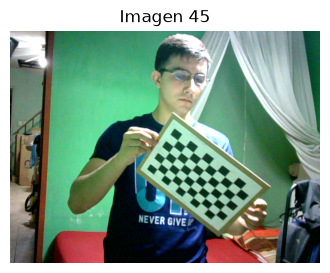

In [26]:
# Imagen capturada de forma aleatoria
index=np.random.randint(len(image_bgr_list))
image_bgr=image_bgr_list[index]
plot_image(image_bgr, title=f"Imagen {index + 1}", figsize=(4,4))

# Guardar imagenes <a class='anchor' id='gi'>

Las imagenes se guardan en formato JPG en el siguiente directorio:
**./calibration images/\<camera name>**

In [27]:
# Ruta donde se guardaran las imagenes
folder_name=os.path.join(os.getcwd(), *['calibration images', camera.name])

# Creamos la carpeta si no existe, y limpiamos la carpeta en caso de que exista
if not os.path.exists(folder_name):
    os.makedirs(folder_name)
else:
    shutil.rmtree(folder_name, ignore_errors=True)
    os.makedirs(folder_name)
    
# Guardamos los datos del tablero de ajedrez
d={
    "chessboard_dimensions": chessboard_dimensions,
    "square_size": square_size
}
with open(os.path.join(folder_name, *['chessboard_information.pkl']), "wb") as file:
    pickle.dump(d, file)
    
# Guardamos las imagenes
for i in range(len(image_bgr_list)):
    image_bgr=image_bgr_list[i]
    # Nombre de la imagen
    image_name=f"img_{str(i + 1).zfill(2)}.jpg"
    full_path=os.path.join(folder_name, *[image_name])
    # Se guarda la imagen
    cv2.imwrite(full_path, image_bgr)

# Leer imagenes <a class='anchor' id='li'>

In [28]:
# Ruta donde se guardaron las imagenes
folder_name=os.path.join(os.getcwd(), *['calibration images', camera.name])

# Cargamos los datos del tablero de ajedrez
d=None
with open(os.path.join(folder_name, *['chessboard_information.pkl']), "rb") as file:
    d=pickle.load(file)

# Leemos las imagenes
image_bgr_list=[]
file_names=sorted(glob.glob(os.path.join(folder_name, *["*.jpg"])))
for file_name in file_names:
    image_brg=cv2.imread(file_name)
    image_bgr_list.append(image_brg)

print(f"Informacion del tablero de ajedrez: {d}")

Informacion del tablero de ajedrez: {'chessboard_dimensions': (9, 6), 'square_size': 25.0}


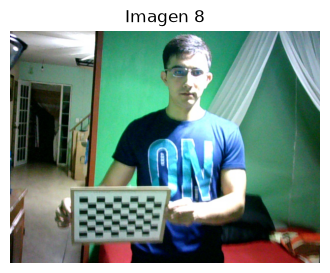

In [29]:
# Imagen aleatoria
index=np.random.randint(len(image_bgr_list))
image_bgr=image_bgr_list[index]
plot_image(image_bgr, title=f"Imagen {index + 1}", figsize=(4,4))